# Images and Text as Numerical Representations
## What do we preserve, what do we lose, and what does “similar” mean?

**Practical 6 — core approximately 65–70 minutes, optional extension up to 85 minutes**

The previous practical worked with probability distributions.  
Now we move to **different data modalities**.

An image and a text document look completely different, but most numerical algorithms eventually need
something like

$$
x \in \mathbb{R}^d.
$$

So the central question is:

> How do we turn a structured object into numbers without forgetting which structure matters?

A useful mental model is

$$
\text{raw object}
\overset{f}{\longrightarrow}
\text{representation}
\longrightarrow
\text{comparison / analysis}.
$$

The representation map $f$ is not neutral. It decides what becomes visible to the next algorithm.

### Learning outcomes

After this session you should be able to:

1. treat an image as a tensor rather than only as a picture
2. distinguish a representation from the original object
3. explain why flattening can preserve values while hiding spatial structure
4. build simple image feature vectors and identify what they discard
5. convert text into count and TF–IDF vectors
6. explain why bag-of-words loses word order
7. compare objects numerically using Euclidean or cosine distance
8. audit a representation by asking what it preserves and what it makes invariant

### Requirements

Core: `numpy`, `pandas`, `matplotlib`, `scikit-learn`.

The notebook uses only small synthetic examples so it can run without external datasets.

### Session plan

| Time | Part | Main idea |
|---|---|---|
| 0–10 min | 1. One object, several representations | representation is a modelling decision |
| 10–30 min | 2. Images | tensor, grayscale, flattening, histograms, spatial loss |
| 30–50 min | 3. Text | tokens, counts, TF–IDF, cosine similarity |
| 50–65 min | 4. Representation changes geometry | distance depends on the representation |
| 65–70 min | 5. Exit challenge | explain preservation and loss |
| 70–85 min | 6. Optional | local structure: n-grams and simple morphology |

The **core is Parts 1–5**.

---
## 0. Environment

In [1]:
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Python:       ", sys.version.split()[0])
print("NumPy:        ", np.__version__)
print("pandas:       ", pd.__version__)
print("scikit-learn: ", __import__("sklearn").__version__)
print("Platform:     ", platform.platform())

Python:        3.13.5
NumPy:         2.3.5
pandas:        2.2.3
scikit-learn:  1.8.0
Platform:      Linux-6.18.44-x86_64-with-glibc2.41


---
## 1. One object can have several useful representations

A representation encodes an object in a form convenient for some operation.

For an image, possibilities include:

- the original pixel tensor
- a flattened vector
- a colour / intensity histogram
- edge or texture features
- regions or a graph

For text:

- the original character sequence
- tokens
- term counts
- TF–IDF
- n-grams
- a graph of extracted relations
- a learned embedding

No single one is simply “the data”.

A disciplined workflow is:

```text
object
↓
what structure matters?
↓
choose representation
↓
choose comparison rule
↓
test counterexamples
```

### Representation audit

For every representation in this practical, ask four questions:

1. **What is preserved?**
2. **What is discarded or hidden?**
3. **What transformations should leave the representation nearly unchanged?**
4. **What notion of distance becomes meaningful?**

We will use these questions repeatedly.

---
## 2. Images: a picture is also an array

A grayscale image can be represented as

$$
I \in \mathbb{R}^{H\times W},
$$

and an RGB image as

$$
I \in \mathbb{R}^{H\times W\times 3}.
$$

The axes themselves carry structure:

- row
- column
- channel

Let us create a few tiny images where we know exactly what changed.

In [2]:
def make_square_image(size=32, top=8, left=8, side=12):
    image = np.zeros((size, size), dtype=float)
    image[top:top + side, left:left + side] = 1.0
    return image


square_center = make_square_image(top=10, left=10)
square_shifted = make_square_image(top=10, left=14)

half_split = np.zeros((32, 32), dtype=float)
half_split[:, :16] = 1.0

checkerboard = (np.indices((32, 32)).sum(axis=0) % 2).astype(float)

images = {
    "center square": square_center,
    "shifted square": square_shifted,
    "half split": half_split,
    "checkerboard": checkerboard,
}

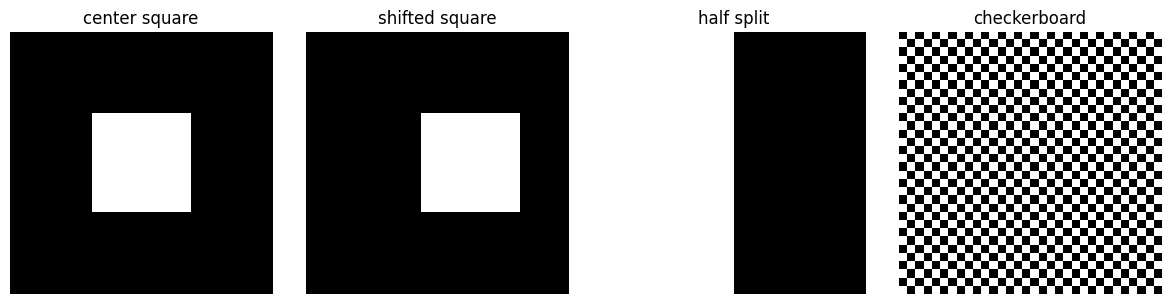

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.1 Shape, dtype, and pixel meaning

Before any transformation, inspect the representation itself.

A value of `1.0` in our synthetic image means “white” only because **we defined it that way**.
In a real dataset a pixel might represent encoded colour, reflectance, probability, a mask, or another
measurement.

In [4]:
for name, image in images.items():
    print(
        f"{name:16s}",
        "shape =", image.shape,
        "dtype =", image.dtype,
        "min/max =", (image.min(), image.max()),
    )

center square    shape = (32, 32) dtype = float64 min/max = (np.float64(0.0), np.float64(1.0))
shifted square   shape = (32, 32) dtype = float64 min/max = (np.float64(0.0), np.float64(1.0))
half split       shape = (32, 32) dtype = float64 min/max = (np.float64(0.0), np.float64(1.0))
checkerboard     shape = (32, 32) dtype = float64 min/max = (np.float64(0.0), np.float64(1.0))


### 2.2 Flattening: reversible values, hidden neighbourhood

For fixed shape and a known ordering,

```python
image.reshape(-1)
```

does not lose pixel values.

But it hides the fact that nearby positions in the original tensor were spatial neighbours.

In [5]:
flat = square_center.reshape(-1)

print("image shape:", square_center.shape)
print("flat shape: ", flat.shape)
print("same number of values:", square_center.size == flat.size)

reconstructed = flat.reshape(square_center.shape)
print("exact reconstruction:", np.array_equal(square_center, reconstructed))

image shape: (32, 32)
flat shape:  (1024,)
same number of values: True
exact reconstruction: True


This distinction matters:

> **information stored** and **structure exposed to an algorithm** are not the same thing.

### 2.3 Pixel-space distance can dislike translation

The two square images contain the same shape, only shifted horizontally.

Yet Euclidean distance between flattened pixels changes because many individual pixel coordinates
changed.

In [6]:
def euclidean(a, b):
    return np.linalg.norm(a - b)


d_same = euclidean(square_center.reshape(-1), square_center.reshape(-1))
d_shift = euclidean(square_center.reshape(-1), square_shifted.reshape(-1))

print(f"distance(center, center):  {d_same:.3f}")
print(f"distance(center, shifted): {d_shift:.3f}")

distance(center, center):  0.000
distance(center, shifted): 9.798


Pixel-space Euclidean distance therefore encodes a strong assumption:

> the same content at different pixel coordinates is different.

That may be exactly right for some tasks and undesirable for others.

### 2.4 Histogram: robust to layout, blind to layout

An intensity histogram records how many pixels fall into intensity ranges.

It intentionally discards **where** those pixels occur.

In [7]:
def intensity_histogram(image, bins=8):
    hist, edges = np.histogram(
        image,
        bins=bins,
        range=(0.0, 1.0),
    )
    return hist, edges


hist_split, _ = intensity_histogram(half_split)
hist_checker, edges = intensity_histogram(checkerboard)

print("half split histogram:  ", hist_split)
print("checkerboard histogram:", hist_checker)
print("identical histograms:", np.array_equal(hist_split, hist_checker))

half split histogram:   [512   0   0   0   0   0   0 512]
checkerboard histogram: [512   0   0   0   0   0   0 512]
identical histograms: True


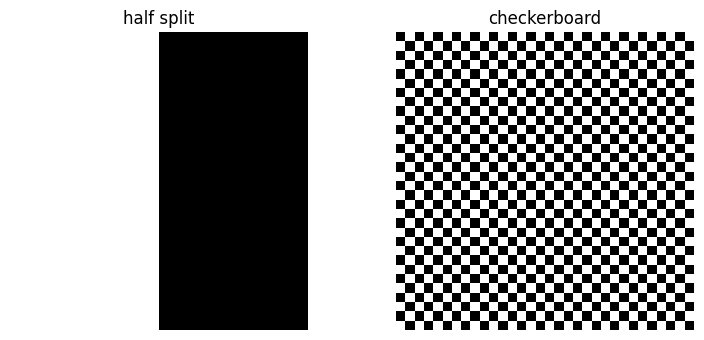

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

axes[0].imshow(half_split, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("half split")
axes[0].axis("off")

axes[1].imshow(checkerboard, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("checkerboard")
axes[1].axis("off")

plt.tight_layout()
plt.show()

These two images have completely different spatial structure but the same intensity histogram.

So a histogram preserves something useful:

- global intensity distribution

and deliberately loses something else:

- spatial arrangement.

That is not automatically a bug. It depends on the task.

### Exercise A — representation counterexample

Create another `32 × 32` binary image with exactly half white pixels and half black pixels, but with a
different spatial arrangement.

Then verify:

1. its histogram matches `half_split`
2. its flattened Euclidean distance from `half_split` is not zero

Write one sentence explaining what the histogram considers “the same”.

In [9]:
# Your solution starts here.

---
## 3. Text: from a sequence to a vector

Raw text is an ordered sequence of symbols.

A classical statistical pipeline is

```text
document
↓
tokenize / normalize
↓
vocabulary
↓
count or weight terms
↓
vector in R^V
```

The important point is that the vectorizer defines a **new representation** of the document.

In [10]:
documents = [
    "the cat chased the mouse",
    "the mouse chased the cat",
    "fast cache gives low latency",
    "slow cache miss gives high latency",
]

for i, doc in enumerate(documents):
    print(i, ":", doc)

0 : the cat chased the mouse
1 : the mouse chased the cat
2 : fast cache gives low latency
3 : slow cache miss gives high latency


### 3.1 Bag of words

A unigram count vector records how often each vocabulary term occurs.

It does **not** retain word order.

In [11]:
count_vectorizer = CountVectorizer()

X_count = count_vectorizer.fit_transform(documents)

vocabulary = count_vectorizer.get_feature_names_out()

count_df = pd.DataFrame(
    X_count.toarray(),
    columns=vocabulary,
    index=[f"doc_{i}" for i in range(len(documents))],
)

count_df

,cache,cat,chased,fast,gives,high,latency,low,miss,mouse,slow,the
doc_0,0,1,1,0,0,0,0,0,0,1,0,2
doc_1,0,1,1,0,0,0,0,0,0,1,0,2
doc_2,1,0,0,1,1,0,1,1,0,0,0,0
doc_3,1,0,0,0,1,1,1,0,1,0,1,0


Look at the first two rows.

The sentences

```text
the cat chased the mouse
the mouse chased the cat
```

have different order but the same unigram counts.

In [12]:
print(
    "doc_0 and doc_1 have identical count vectors:",
    np.array_equal(
        X_count[0].toarray(),
        X_count[1].toarray(),
    ),
)

doc_0 and doc_1 have identical count vectors: True


Bag-of-words is therefore intentionally lossy.

It preserves lexical frequency, but discards most syntax and ordering.

A representation can be useful **because** it removes information — if the removed information is not
important for the task.

### 3.2 TF–IDF: not all terms should have the same weight

Raw counts give frequent terms large values.

TF–IDF combines:

- term frequency in this document
- inverse document frequency across the corpus

so terms common everywhere receive less weight than terms that are more distinctive.

In [13]:
tfidf = TfidfVectorizer()

X_tfidf = tfidf.fit_transform(documents)

tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=[f"doc_{i}" for i in range(len(documents))],
)

tfidf_df.round(3)

,cache,cat,chased,fast,gives,high,latency,low,miss,mouse,slow,the
doc_0,0.000,0.378,0.378,0.000,0.000,0.000,0.000,0.000,0.000,0.378,0.000,0.756
doc_1,0.000,0.378,0.378,0.000,0.000,0.000,0.000,0.000,0.000,0.378,0.000,0.756
doc_2,0.401,0.000,0.000,0.509,0.401,0.000,0.401,0.509,0.000,0.000,0.000,0.000
doc_3,0.357,0.000,0.000,0.000,0.357,0.453,0.357,0.000,0.453,0.000,0.453,0.000


### 3.3 Cosine similarity

Once documents are vectors, we can define a geometry.

Cosine similarity is

$$
\cos(x,y)
=
\frac{x^\top y}{\lVert x\rVert_2\lVert y\rVert_2}.
$$

It compares **direction** rather than raw vector length.

In [14]:
similarity = cosine_similarity(X_tfidf)

similarity_df = pd.DataFrame(
    similarity,
    index=[f"doc_{i}" for i in range(len(documents))],
    columns=[f"doc_{i}" for i in range(len(documents))],
)

similarity_df.round(3)

,doc_0,doc_1,doc_2,doc_3
doc_0,1.0,1.0,0.00,0.00
doc_1,1.0,1.0,0.00,0.00
doc_2,0.0,0.0,1.00,0.43
doc_3,0.0,0.0,0.43,1.00


The first two documents have cosine similarity `1.0` under unigram TF–IDF because their vectors are
identical.

That does **not** mean the sentences have the same meaning.

It means:

> this particular representation cannot distinguish them.

### Vocabulary is part of the fitted representation

A vectorizer fitted on one corpus defines a coordinate system.

A new word absent from that fitted vocabulary has no coordinate.

In [15]:
new_document = ["the cat escaped through the window"]

new_vector = tfidf.transform(new_document)

print("known vocabulary:", tfidf.get_feature_names_out())
print("new document vector:", new_vector.toarray().round(3))

known vocabulary: ['cache' 'cat' 'chased' 'fast' 'gives' 'high' 'latency' 'low' 'miss'
 'mouse' 'slow' 'the']
new document vector: [[0.    0.447 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.894]]


This is why vocabulary and IDF statistics must be fitted on training data only in a predictive pipeline.

The representation itself is learned from the corpus even though no neural network is involved.

### Exercise B — change the representation, change the similarity

Add these two documents:

```text
"battery life is not good"
"battery life is good"
```

1. Fit a unigram TF–IDF representation.
2. Compute their cosine similarity.
3. Explain why a high similarity can be misleading.
4. State one representation change that could preserve more local order.

In [16]:
# Your solution starts here.

---
## 4. Representation changes geometry

After vectorization, both images and documents may look like vectors in $\mathbb R^d$.

But this does **not** make their coordinates equally meaningful.

For images:

```text
flattened pixels
→ Euclidean distance
```

means “compare corresponding pixel positions”.

For TF–IDF:

```text
term weights
→ cosine similarity
```

means “compare weighted lexical direction”.

The geometry comes from **both**:

1. the representation
2. the comparison rule

### Same object, different notion of similarity

Consider the image pair:

```text
center square ↔ shifted square
```

and the text pair:

```text
"the cat chased the mouse"
↔
"the mouse chased the cat"
```

In both examples, one representation makes an important structural change look either too large or
invisible.

This gives us a general rule:

> Before trusting a distance, inspect what the representation makes near and far.

### A representation checklist

Before sending data into PCA, clustering, nearest-neighbour search, or a machine-learning model, ask:

| Question | Image example | Text example |
|---|---|---|
| What is the original structure? | 2-D neighbourhood + channels | ordered token sequence |
| What becomes a coordinate? | pixel / feature value | term weight |
| What is lost? | perhaps layout or colour | perhaps order / syntax |
| Desired invariance? | translation, lighting? | case, spelling, paraphrase? |
| Distance? | Euclidean? histogram distance? | cosine? |
| Counterexample? | same histogram, different layout | same BoW, different order |

This is the bridge to the later lectures on dimensionality reduction, clustering and learned embeddings.

---
## 5. Exit challenge — representation audit

Choose **one image pair** and **one text pair** from this notebook.

For each pair, complete this table in Markdown:

| Item | Image pair | Text pair |
|---|---|---|
| Original structure |  |  |
| Representation used |  |  |
| Comparison rule |  |  |
| What is preserved? |  |  |
| What is lost / hidden? |  |  |
| One useful invariance |  |  |
| One counterexample / failure mode |  |  |

Then write **three short conclusions**:

1. why representation choice matters before clustering or classification
2. why “vectorized” does not mean “all structure was preserved”
3. why there is no universally best representation independent of the task

In [17]:
# Optional: use this cell for extra checks supporting the exit challenge.

---
## 6. Optional extension — preserving more local structure

Skip this section if the core practical has already used the available class time.

### 6.1 Text n-grams

A unigram representation loses word order.

Bigrams retain local two-token sequences, so reordered sentences can become distinguishable.

In [18]:
bigram_vectorizer = CountVectorizer(ngram_range=(1, 2))

X_bigram = bigram_vectorizer.fit_transform(documents[:2])

bigram_df = pd.DataFrame(
    X_bigram.toarray(),
    columns=bigram_vectorizer.get_feature_names_out(),
    index=["doc_0", "doc_1"],
)

bigram_df

,cat,cat chased,chased,chased the,mouse,mouse chased,the,the cat,the mouse
doc_0,1,1,1,1,1,0,2,1,1
doc_1,1,0,1,1,1,1,2,1,1


In [19]:
print(
    "identical unigram count vectors:",
    np.array_equal(
        X_count[0].toarray(),
        X_count[1].toarray(),
    ),
)

print(
    "identical unigram+bigram vectors:",
    np.array_equal(
        X_bigram[0].toarray(),
        X_bigram[1].toarray(),
    ),
)

identical unigram count vectors: True
identical unigram+bigram vectors: False


The cost is a larger and sparser feature space.

Preserving more structure is rarely free.

### 6.2 Binary morphology: representation plus scale

For a binary image, foreground pixels can be treated as a set.

A simple dilation expands that set; erosion shrinks it.

These operations are scale-dependent because the structuring element defines what counts as a “small”
gap or object.

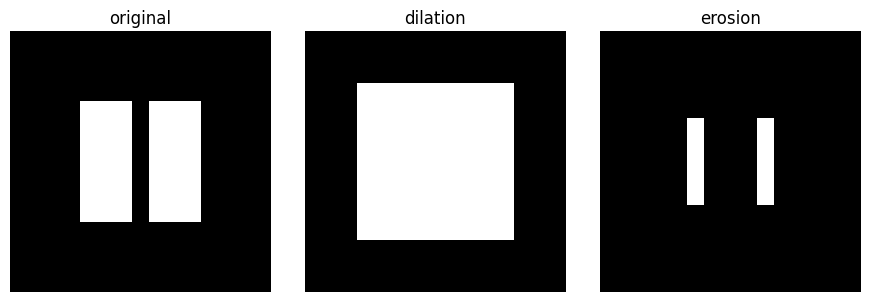

In [20]:
try:
    from scipy import ndimage
except ImportError:
    ndimage = None

binary = np.zeros((15, 15), dtype=bool)
binary[4:11, 4:7] = True
binary[4:11, 8:11] = True

if ndimage is not None:
    structure = np.ones((3, 3), dtype=bool)

    dilated = ndimage.binary_dilation(binary, structure=structure)
    eroded = ndimage.binary_erosion(binary, structure=structure)

    fig, axes = plt.subplots(1, 3, figsize=(9, 3))

    for ax, image, title in zip(
        axes,
        [binary, dilated, eroded],
        ["original", "dilation", "erosion"],
    ):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("SciPy is not installed; skip the morphology extension.")

The important point is not the SciPy function.

It is the modelling decision:

> a three-pixel gap is “small” only relative to the image resolution and the chosen structuring element.

---
## Summary

### 1. Representation comes before algorithm

An algorithm does not see “an image” or “a document”. It sees the representation we provide.

### 2. Loss can be intentional

- flattening preserves pixel values but hides 2-D neighbourhood
- histograms preserve global intensity frequencies but discard layout
- bag-of-words preserves term counts but discards most order
- TF–IDF reweights terms according to corpus-level statistics

### 3. Distance is part of the model

Euclidean distance and cosine similarity only become meaningful after we decide what the coordinates
mean.

### 4. Counterexamples are powerful

If two objects that should be different receive identical representations, the representation cannot solve
that task by itself.

The next practical extends the same reasoning to **time series and graphs**, where temporal order and
relational structure create different kinds of constraints.

### Further reading

- [NumPy: array manipulation](https://numpy.org/doc/stable/reference/routines.array-manipulation.html)
- [scikit-learn: text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)
- [scikit-learn: cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
- [SciPy ndimage](https://docs.scipy.org/doc/scipy/reference/ndimage.html)